In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import  matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [3]:
df=pd.read_csv("data\insurance.csv")

# Eda

In [4]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
df.shape

(1338, 7)

In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [9]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(1)

In [29]:
target_feature = 'charges'

In [12]:
numeric_features = df.select_dtypes(exclude='object').columns.tolist()
categorical_features = df.select_dtypes(include='object').columns.tolist()

In [13]:
numeric_features

['age', 'bmi', 'children', 'charges']

In [14]:
categorical_features

['sex', 'smoker', 'region']

#Univariate Analysis


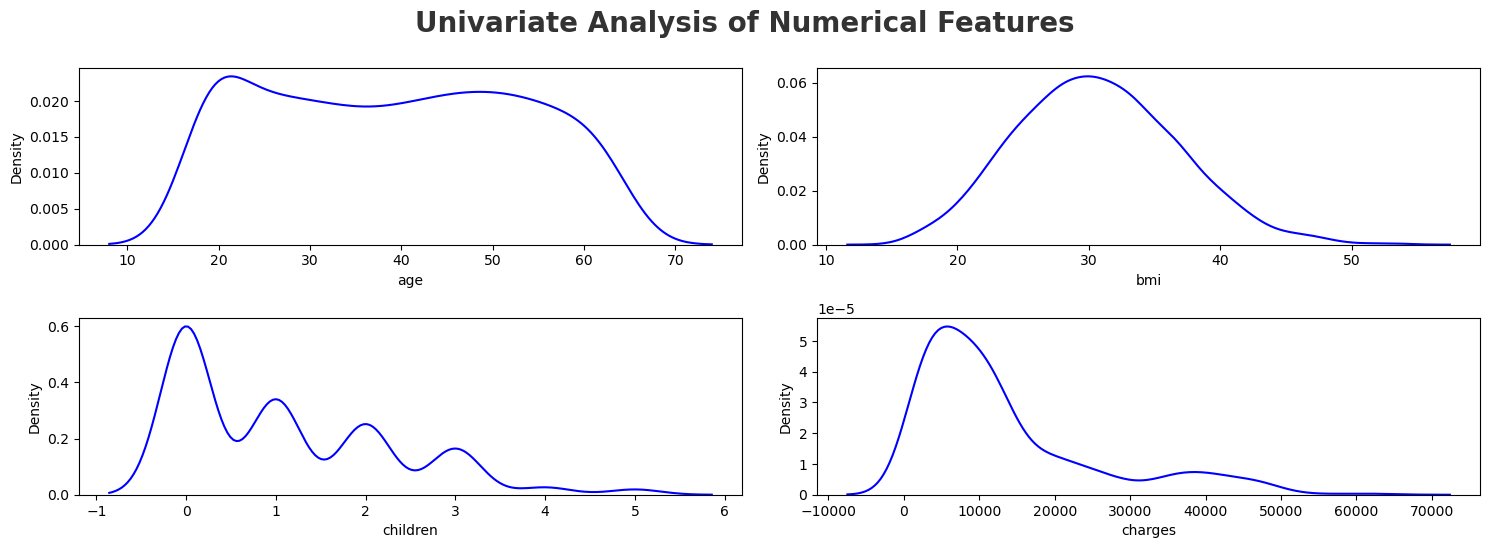

In [15]:
plt.figure(figsize=(15, 10))
plt.suptitle('Univariate Analysis of Numerical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)

for i in range(0, len(numeric_features)):
    plt.subplot(4, 2, i+1)
    sns.kdeplot(x=df[numeric_features[i]], color='blue')
    plt.xlabel(numeric_features[i])
    plt.tight_layout()

In [16]:
categorical_columns = []

for i in categorical_features:

    print(f'{i}: {len(df[i].unique())}')

    if len(df[i].unique()) < 10:
        categorical_columns.append(i)

sex: 2
smoker: 2
region: 4


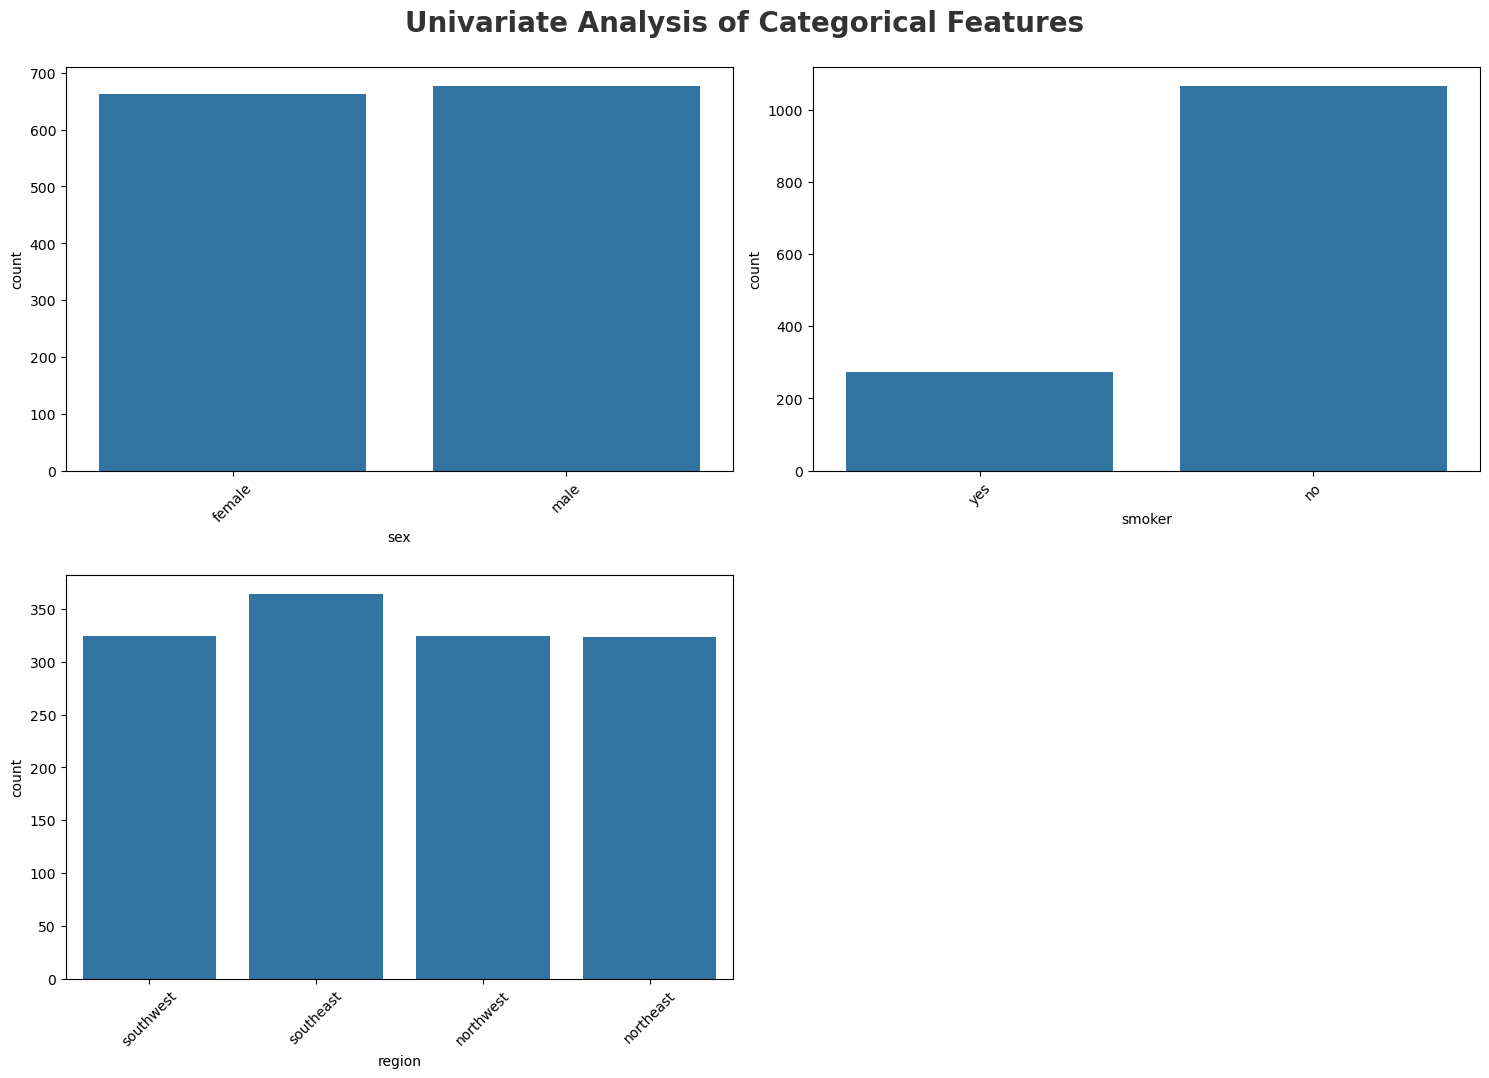

In [17]:
# categorical columns
plt.figure(figsize=(15, 20))
plt.suptitle('Univariate Analysis of Categorical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)
for i in range(0, len(categorical_columns)):
    plt.subplot(4, 2, i+1)
    sns.countplot(x=df[categorical_columns[i]])
    plt.xlabel(categorical_columns[i])
    plt.xticks(rotation=45)
    plt.tight_layout()

#univarint

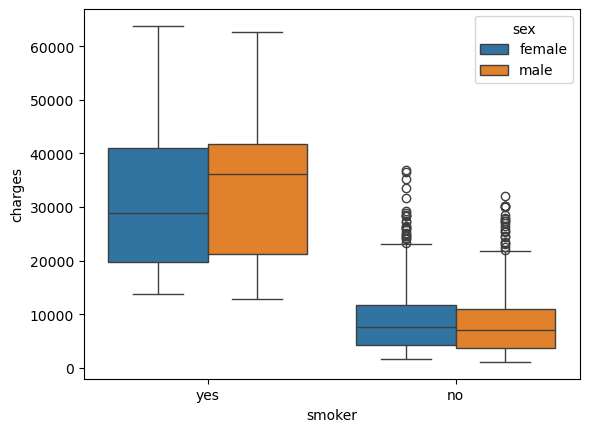

In [24]:
sns.boxplot(x="smoker", y="charges",hue="sex" ,data=df)
plt.show()

<Axes: xlabel='region', ylabel='charges'>

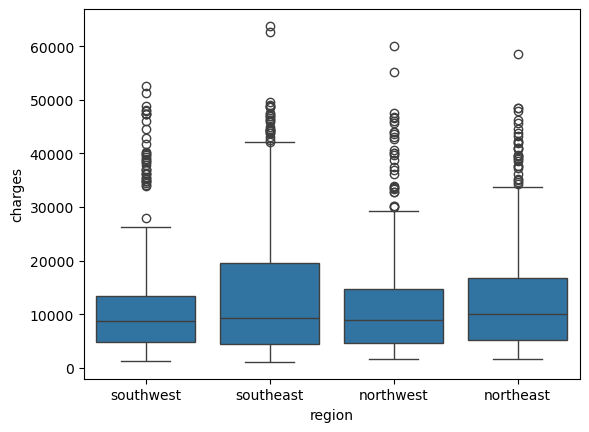

In [25]:
sns.boxplot(x="region",y="charges",data=df)

In [26]:
df.corr(numeric_only=True)

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


<Axes: >

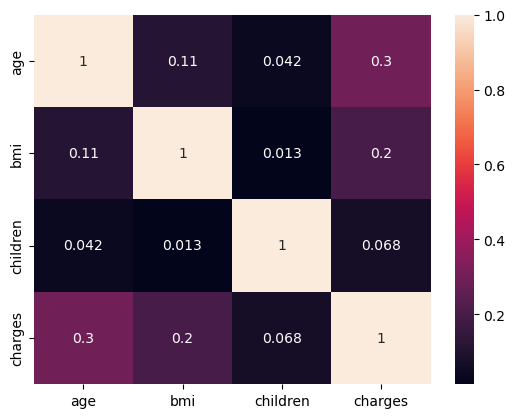

In [27]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

Relationship between target and numerical columns

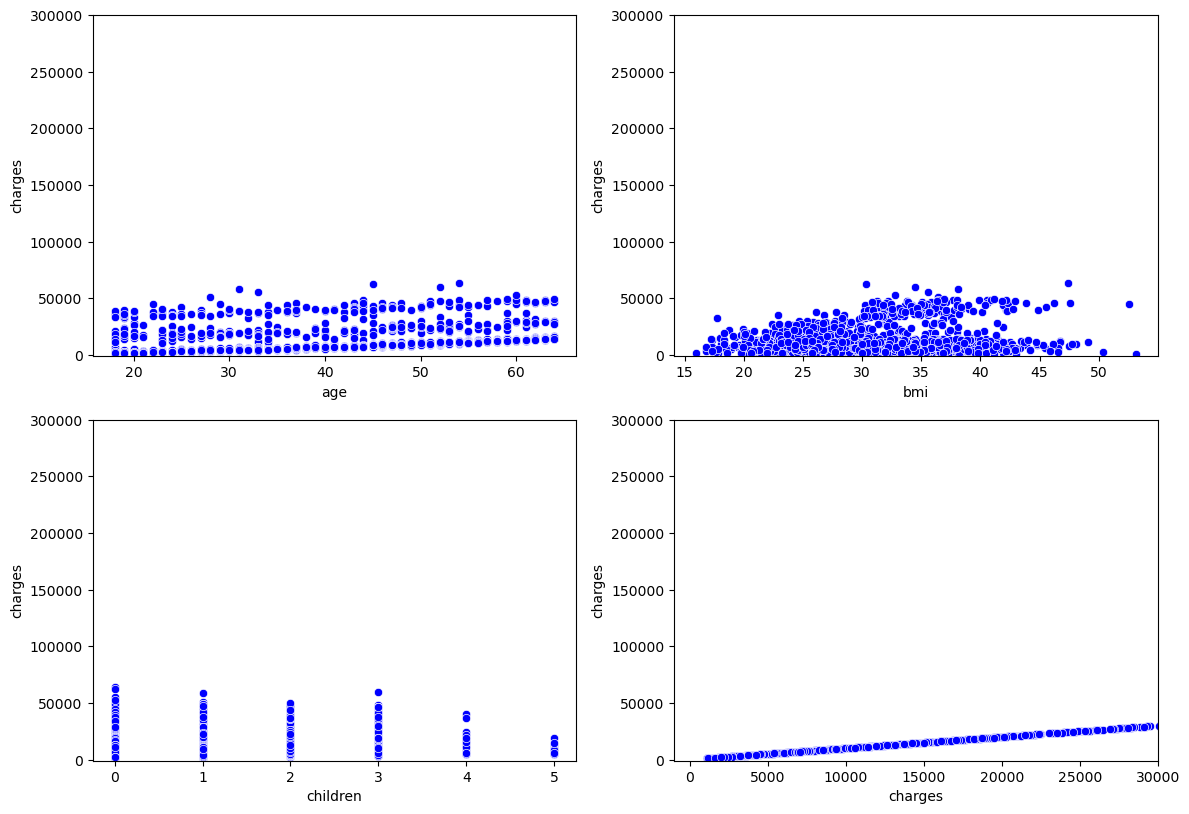

In [30]:
fig = plt.figure(figsize=(12, 24))

for i in range(0, len(numeric_features)):
    ax = plt.subplot(6, 2, i+1)
    sns.scatterplot(data= df ,y=target_feature, x=numeric_features[i], color='b')
    if df[numeric_features[i]].max() > 30000:
        plt.xlim(-1000,30000)
    if df[numeric_features[i]].max() > 3000000:
        plt.xlim(-1000,3000000)
    plt.ylim(-1000, 300000)
    plt.tight_layout()

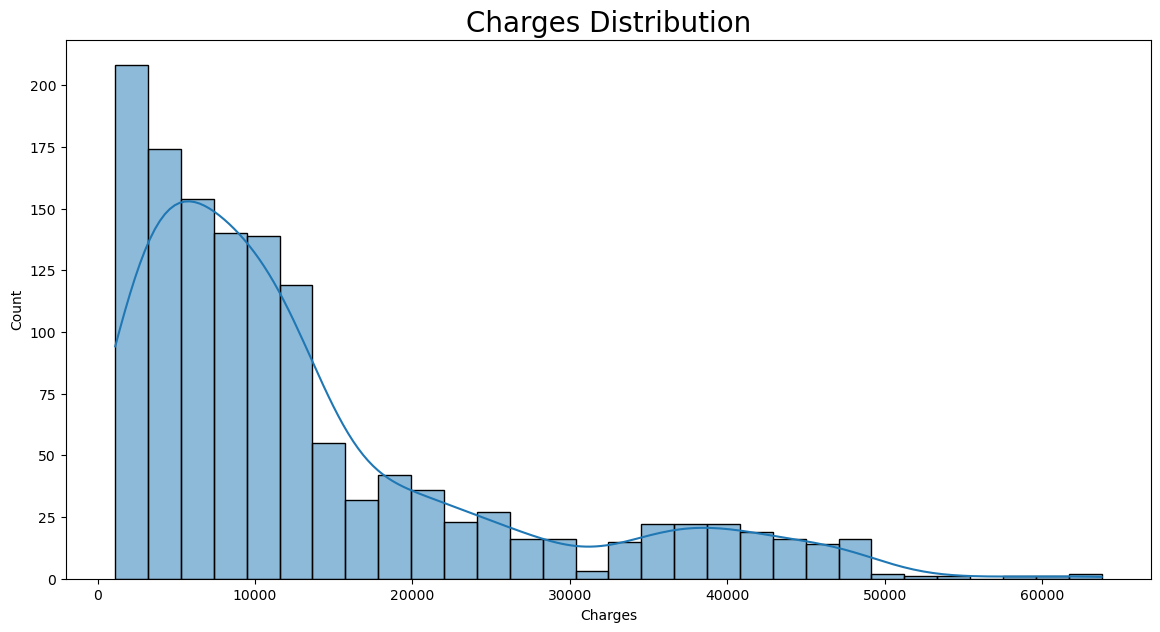

In [33]:
plt.figure(figsize=(14, 7))

sns.histplot(
    data=df,
    x="charges",
    bins=30,
    kde=True
)

plt.title("Charges Distribution", fontsize=20)
plt.xlabel("Charges")
plt.ylabel("Count")

plt.show()

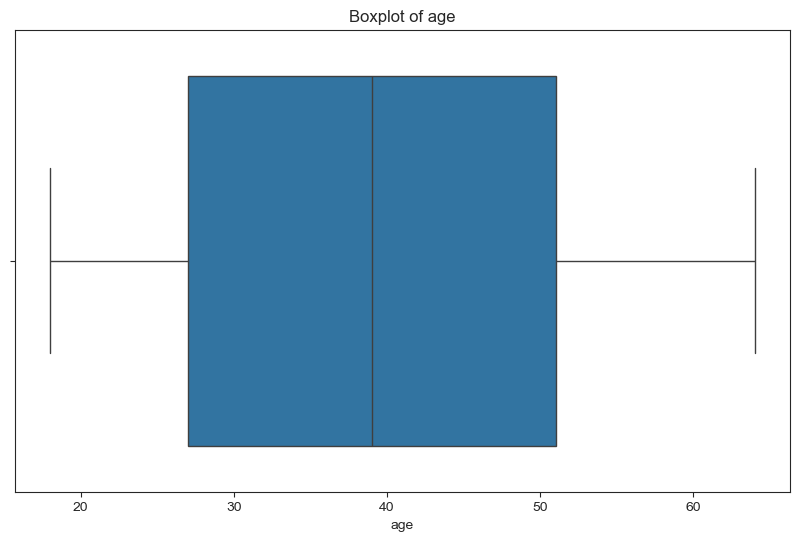

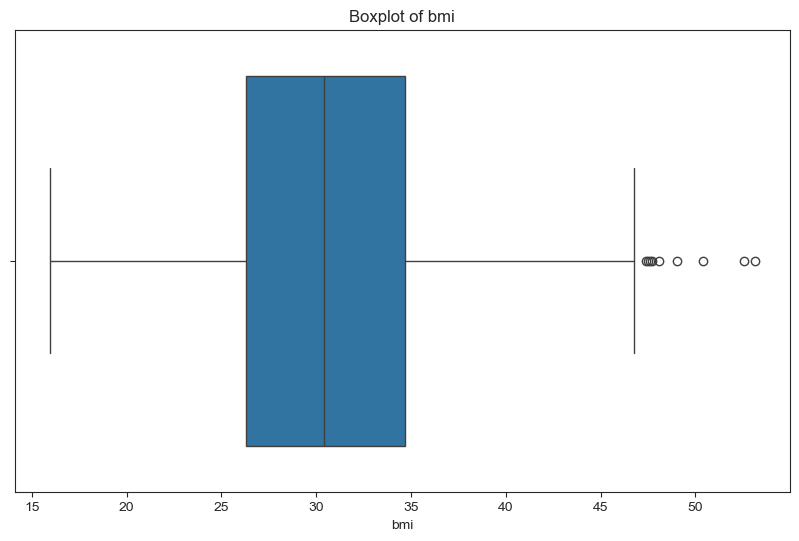

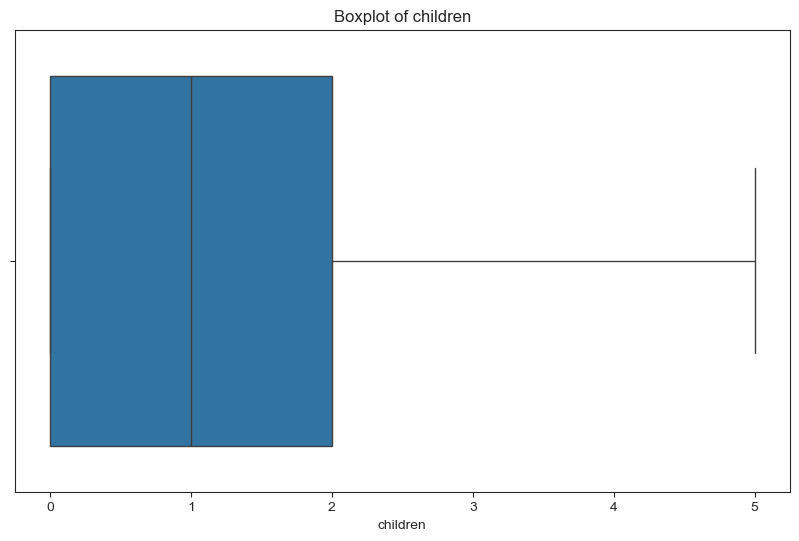

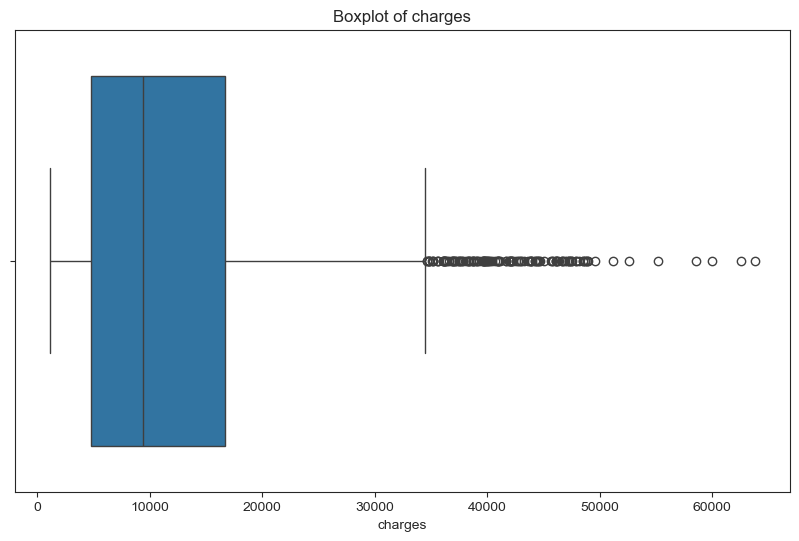

In [36]:
for i in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.set_style("ticks")

    ax = sns.boxplot(x=df[i])

    plt.title(f"Boxplot of {i}")
    plt.show()

#data clening preprocesing

In [38]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

no clening reqired data is alredy claen

# feature eningering

In [39]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer, LabelEncoder, OrdinalEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

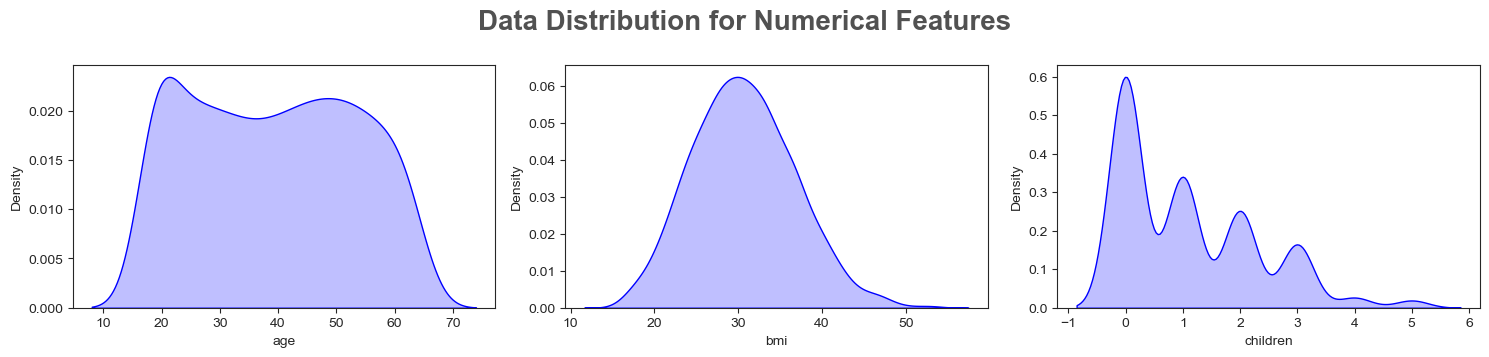

In [57]:
plt.figure(figsize=(15, 15))
plt.suptitle('Data Distribution for Numerical Features', fontsize=20, fontweight='bold', alpha=0.8, y=1.)

for i in range(0, len(numeric_features)):
    plt.subplot(5, 3, i+1)
    sns.kdeplot(x=df[numeric_features[i]],shade=True, color='b')
    plt.xlabel(numeric_features[i])
    plt.tight_layout()

In [58]:
df[numeric_features].skew()

age         0.055673
bmi         0.284047
children    0.938380
dtype: float64

In [107]:
outlier_feature=["bmi"]

In [102]:
x=df.drop("charges",axis=1)
y=df["charges"]
y = np.log1p(y)

In [105]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [106]:
X_train

,age,sex,bmi,children,smoker,region
560,46,female,19.950,2,no,northwest
1285,47,female,24.320,0,no,northeast
1142,52,female,24.860,0,no,southeast
969,39,female,34.320,5,no,southeast
486,54,female,21.470,3,no,northwest
...,...,...,...,...,...,...
1095,18,female,31.350,4,no,northeast
1130,39,female,23.870,5,no,southeast
1294,58,male,25.175,0,no,northeast
860,37,female,47.600,2,yes,southwest


In [108]:
numeric_features_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', RobustScaler())
])

categorical_features_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('one_hot_encoder', OneHotEncoder()),
]
)

outliers_features_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('transformer', PowerTransformer(standardize=True))
])

preprocessor = ColumnTransformer(
    [
        ("Numeric Pipeline",numeric_features_pipeline, numeric_features),
        ("Categorical Features Pipeline",categorical_features_pipeline, categorical_features),
        ("Outliers Features Pipeline", outliers_features_pipeline, outlier_feature)
]
)

In [128]:
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [109]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [110]:
def evaluate_reg(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

In [130]:
models = {
    "Linear Regression": LinearRegression()
}

model_list = []
r2_score_list = []

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)

    # Make Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Evaluate Train and Test dataset
    model_train_mae, model_train_rmse, model_train_r2 = evaluate_reg(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = evaluate_reg(y_test, y_test_pred)

    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])

    print('Model performance for Training set')
    print("- RMSE: {:.4f}".format(model_train_rmse))
    print("- MAE: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print('----------------------------------')

    print('Model performance for Test set')
    print("- RMSE: {:.4f}".format(model_test_rmse))
    print("- MAE: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    r2_score_list.append(model_test_r2)

    print('='*35)
    print('\n')


Linear Regression
Model performance for Training set
- RMSE: 0.4484
- MAE: 0.2825
- R2 Score: 0.7577
----------------------------------
Model performance for Test set
- RMSE: 0.4188
- MAE: 0.2705
- R2 Score: 0.8049




In [112]:
import joblib

joblib.dump(models, "insurance_model.pkl")

['insurance_model.pkl']

In [116]:
import joblib

model = joblib.load("model/insurance_model.pkl")

print(type(model))

<class 'dict'>


In [118]:
import joblib

model_data = joblib.load("model/insurance_model.pkl")

print(type(model_data))
print(model_data.keys())

<class 'dict'>
dict_keys(['Linear Regression'])


In [120]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

print(final_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('Numeric Pipeline',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['age', 'children']),
                                                 ('Categorical Features '
                                                  'Pipeline',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('one_hot_encoder',
                                                                   OneHotEncoder())]),
   

In [124]:
# Recreate the original DataFrame splits
X_train_df, X_test_df, y_train_final, y_test_final = train_test_split(
    x, y, test_size=0.2, random_state=42
)

# Fit the complete pipeline on raw DataFrames
final_model.fit(X_train_df, y_train_final)

# Make predictions
y_test_pred_final = final_model.predict(X_test_df)

print("Model fitted successfully.")

Model fitted successfully.


In [125]:
joblib.dump(
    final_model,
    "insurance_model.pkl"
)

['insurance_model.pkl']

In [126]:
model = joblib.load("insurance_model.pkl")

print(type(model))

<class 'sklearn.pipeline.Pipeline'>


In [127]:
import os

print(os.path.abspath("insurance_model.pkl"))

c:\Users\Lenovo\OneDrive\Desktop\Insurance Prediction\insurance_model.pkl
